# Projet 4 : Classifiez automatiquement des informations

## Modélisation et optimisation

### 1 - Chargement des librairies 

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

# Visualisation 
import seaborn as sns
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

# metriques
from sklearn.metrics import roc_curve, precision_recall_curve, f1_score, precision_score, recall_score

# Modeles
from sklearn.dummy import DummyClassifier # Attention : ne pas confondre DummyClassifier et DummyRegressor
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier


In [4]:
# parametre pandas pour afficher toutes les colonnes (sans troncature)
pd.set_option('display.max_columns', None)

### 2 - Chargement du fichier join allégé

In [5]:
DATA_PROCESSED = Path("../Data/Processed")

df_join_light = pd.read_csv(DATA_PROCESSED / "dataset_join_light.csv")

In [6]:
df_join_light

,Unnamed: 0,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,domaine_etude,frequence_deplacement,annees_depuis_la_derniere_promotion,satisfaction_employee_environnement,note_evaluation_precedente,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,8,6,4,Oui,0,0,1,2,Infra & Cloud,Occasionnel,0,2,3,4,1,1,3,Oui,11 %
1,1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,10,10,7,Non,1,3,8,1,Infra & Cloud,Frequent,1,3,2,2,4,3,4,Non,23 %
2,2,4,37,M,2090,Célibataire,Consulting,Consultant,6,7,0,0,Oui,0,3,2,2,Autre,Occasionnel,0,4,2,3,2,3,3,Oui,15 %
3,3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,8,8,7,Non,0,3,3,4,Infra & Cloud,Frequent,3,4,3,3,3,3,3,Oui,11 %
4,4,7,27,M,3468,Marié(e),Consulting,Consultant,9,6,2,2,Non,1,3,2,1,Transformation Digitale,Occasionnel,2,1,3,2,4,3,3,Non,12 %
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,1465,2061,36,M,2571,Marié(e),Consulting,Consultant,4,17,5,2,Non,1,3,23,2,Transformation Digitale,Frequent,0,3,4,4,3,3,3,Non,17 %
1466,1466,2062,39,M,9991,Marié(e),Consulting,Manager,4,9,7,7,Non,1,5,6,1,Transformation Digitale,Occasionnel,1,4,2,1,1,3,3,Non,15 %
1467,1467,2064,27,M,6142,Marié(e),Consulting,Tech Lead,1,6,6,2,Non,1,0,4,3,Infra & Cloud,Occasionnel,0,2,4,2,2,3,4,Oui,20 %
1468,1468,2065,49,M,5390,Marié(e),Commercial,Cadre Commercial,2,17,9,6,Non,0,3,2,3,Transformation Digitale,Frequent,0,4,2,2,4,2,3,Non,14 %


### 3 - Feature Engineering

FE1_tranche_salariale    
1 2 3 4 pour (0 - 5000 - 10000 - 15000 - 20000)

In [7]:
# Création de FE1
df_join_light['FE1_tranche_salariale'] = pd.cut(
    df_join_light['revenu_mensuel'],
    bins=[-1, 5000, 10000, 15000, 20000],
    labels=[1, 2, 3, 4],
)

In [8]:
# Suppression de la variable revenu_mensuel
df_join_light.drop(columns="revenu_mensuel", inplace= True)

/var/folders/hz/20lsg3ts225gnwvs2h1461bc0000gn/T/ipykernel_14811/1265739694.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_join_light.drop(columns="revenu_mensuel", inplace= True)


FE2_satisfaction_globale    
Somme des valeurs des variables de satisfations (note sur 16)

In [9]:
# Création de FE2
df_join_light['FE2_satisfaction_globale'] = (df_join_light['satisfaction_employee_environnement'] + 
                                             df_join_light['satisfaction_employee_equilibre_pro_perso'] +
                                             df_join_light['satisfaction_employee_equipe'] +
                                             df_join_light['satisfaction_employee_nature_travail'])


In [10]:
# Suppression des variables liées aux satisfactions
df_join_light.drop(columns=['satisfaction_employee_environnement', 'satisfaction_employee_equilibre_pro_perso','satisfaction_employee_equipe', 'satisfaction_employee_nature_travail' ], 
                   inplace= True)

/var/folders/hz/20lsg3ts225gnwvs2h1461bc0000gn/T/ipykernel_14811/1975434235.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_join_light.drop(columns=['satisfaction_employee_environnement', 'satisfaction_employee_equilibre_pro_perso','satisfaction_employee_equipe', 'satisfaction_employee_nature_travail' ],


Tranche d'age 1 2 3 4 5 pour (0-20-30-40-50-60)

In [11]:
# Création de FE3
df_join_light['FE3_tranche_age'] = pd.cut(
    df_join_light['age'],
    bins=[-1, 20, 30, 40, 50, 60],
    labels=[1, 2, 3, 4, 5],
)

In [12]:
# Suppression de la variable age
df_join_light.drop(columns="age", inplace= True)

/var/folders/hz/20lsg3ts225gnwvs2h1461bc0000gn/T/ipykernel_14811/3201082191.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_join_light.drop(columns="age", inplace= True)


Suppression de la variable Unnamed: 0 qui a été créé a la suite de la création du CSV "brut_join_light.csv"

In [13]:
df_join_light.drop(columns="Unnamed: 0", inplace= True)

/var/folders/hz/20lsg3ts225gnwvs2h1461bc0000gn/T/ipykernel_14811/2178402836.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_join_light.drop(columns="Unnamed: 0", inplace= True)


Suppression de la variable id_employee (elle a servi pour la jointure uniquement)    
Il ne sera pas nécessaire d'identifier un employé spécifique

In [14]:
df_join_light.drop(columns="id_employee", inplace=True)

/var/folders/hz/20lsg3ts225gnwvs2h1461bc0000gn/T/ipykernel_14811/4280018764.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_join_light.drop(columns="id_employee", inplace=True)


### 4 -Transformation des données

Suppression des variables non nécessaire a l'apprentissage.    
nombre_participation_pee   
nb_formations_suivies    
domaine_etude

In [15]:
df_join_light.drop(columns=['nombre_participation_pee','nb_formations_suivies', 'domaine_etude'],
                    inplace= True)

/var/folders/hz/20lsg3ts225gnwvs2h1461bc0000gn/T/ipykernel_14811/1950052388.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_join_light.drop(columns=['nombre_participation_pee','nb_formations_suivies', 'domaine_etude'],


Transformation en int64 la variable augementation_salaire_precedente

In [16]:
# Suppression du dernier caractère %
df_join_light['augementation_salaire_precedente'] = df_join_light['augementation_salaire_precedente'].apply(lambda x: x[:-1]) 

# Cast de la colonne en Int64
df_join_light['augementation_salaire_precedente'] = pd.to_numeric(df_join_light['augementation_salaire_precedente'])

Encodage des catégories

In [17]:
# Encodage binaire de la variable genre
df_join_light["genre"] = df_join_light["genre"].map({"M": 0, "F": 1})

# Encodage binaire de la variable heure_supplementaires
df_join_light["heure_supplementaires"] = df_join_light["heure_supplementaires"].map({"Non": 0, "Oui": 1})

# Encodage binaire de la cible a_quitte_l_entreprise
df_join_light["a_quitte_l_entreprise"] = df_join_light["a_quitte_l_entreprise"].map({"Non": 0, "Oui": 1})

# Encodage ordinal de la variable frequence_deplacement
df_join_light["frequence_deplacement"] = df_join_light["frequence_deplacement"].map({"Aucun": 1, "Occasionnel": 2, "Frequent": 3})

# One-Hot Encoding sur la variable statut_marital
df_join_light = pd.get_dummies(df_join_light, columns=['statut_marital'], drop_first=True, dtype=int)

# One-Hot Encoding sur la variable departement
df_join_light = pd.get_dummies(df_join_light, columns=['departement'], drop_first=True, dtype=int)

# Encodage "frequency_count" de la variable poste (elle n'a pas de doublons de valeurs en value_counts() et ca permet d'avoir 1 fréquence différente par catégorie)
freq = df_join_light['poste'].value_counts(normalize=True)
df_join_light['poste'] = df_join_light['poste'].map(freq).round(4)

Normalisation des vatiables numériques 

Pour rappel : 
<table>
  <caption>Les 5 variables les plus asymétriques pour lequelles une conversion en log est nécessaire</caption>
  <thead>
    <tr>
      <th>Nom de la variable</th>
      <th>Etalement a droite </th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>annees_depuis_la_derniere_promotion</td>
      <td>1.984290</td>
    </tr>
    <tr>
      <td>note_evaluation_actuelle</td>
      <td>1.921883</td>
    </tr>
    <tr>
      <td>annees_dans_l_entreprise</td>
      <td>1.764529</td>
    </tr>
    <tr>
      <td>revenu_mensuel</td>
      <td>1.369817</td>
    </tr>
    <tr>
      <td>annee_experience_totale</td>
      <td>1.117172</td>
    </tr>
    <tr>
      <td>nombre_experiences_precedentes</td>
      <td>1.026471</td>
    </tr>
    <tr>
      <td>niveau_hierarchique_poste</td>
      <td>1.025401</td>
    </tr>
  </tbody>
</table>

Etant donné que les variables revenu_mensuel et niveau_hierarchique_poste n'existent plus, je ne les ajoute pas a la liste de conversion en log

In [18]:
# Mise a l'échelle log des variables a forte asymétrie 
colonnes_log = ['annees_depuis_la_derniere_promotion',
                'note_evaluation_actuelle',
                'annees_dans_l_entreprise',
                'annee_experience_totale', 
                'nombre_experiences_precedentes']

df_join_light[colonnes_log] = np.log1p(df_join_light[colonnes_log])

In [19]:
df_join_light

,genre,poste,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,a_quitte_l_entreprise,distance_domicile_travail,niveau_education,frequence_deplacement,annees_depuis_la_derniere_promotion,note_evaluation_precedente,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente,FE1_tranche_salariale,FE2_satisfaction_globale,FE3_tranche_age,statut_marital_Divorcé(e),statut_marital_Marié(e),departement_Consulting,departement_Ressources Humaines
0,1,0.2218,2.197225,2.197225,1.945910,4,1,1,2,2,0.000000,3,1.386294,1,11,2,8,4,0,0,0,0
1,0,0.1986,0.693147,2.397895,2.397895,7,0,8,1,3,0.693147,2,1.609438,0,23,2,12,4,0,1,1,0
2,0,0.1762,1.945910,2.079442,0.000000,0,1,2,2,2,0.000000,2,1.386294,1,15,1,12,3,0,0,1,0
3,1,0.1986,0.693147,2.197225,2.197225,7,0,3,4,3,1.386294,3,1.386294,1,11,1,13,3,0,1,1,0
4,0,0.1762,2.302585,1.945910,1.098612,2,0,2,1,2,1.098612,3,1.386294,0,12,1,10,2,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,0,0.1762,1.609438,2.890372,1.791759,2,0,23,2,3,0.000000,4,1.386294,0,17,1,13,3,0,1,1,0
1466,0,0.0891,1.609438,2.302585,2.079442,7,0,6,1,2,0.693147,2,1.386294,0,15,2,9,3,0,1,1,0
1467,0,0.0986,0.693147,1.945910,1.945910,2,0,4,3,2,0.000000,4,1.609438,1,20,2,9,2,0,1,1,0
1468,0,0.2218,1.098612,2.890372,2.302585,6,0,2,3,3,0.000000,2,1.386294,0,14,2,12,4,0,1,0,0


Création du CSV correspondant au dataset 'ready_to_ML'

In [20]:
df_join_light.to_csv(DATA_PROCESSED / "dataset_join_ready_to_ml.csv")

Split des jeux de train/test

In [21]:
# dataset X pour les features et y pour la cible
X = df_join_light.drop(columns='a_quitte_l_entreprise')
y = df_join_light['a_quitte_l_entreprise']

# split des dataset pour l'entrainnement et le test final
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Min-Max Scaler

In [22]:
# Création d'une liste des colonnes numériques type 'float64'
colonnes_numeriques = X_train.select_dtypes(include="number").columns.tolist()

# Création d'un objet de la classe ColumnTransformer pour y stocker le scaling 'propre'
preprocessor = ColumnTransformer(
    [("scale", MinMaxScaler(), colonnes_numeriques)],
    remainder="passthrough",   # les autres colonnes restent inchangées
)

### 5 - Modelisation

Préparation des pipelines + Type de cross validate

In [23]:
# Choix du cross validate (commun aux modeles testés)
# random_state doit etre identique a celui du split
crossVal_method = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Création des pipelines pour chaque modele testé
pipe_dummy  = Pipeline([("model", DummyClassifier(strategy="stratified"))])
pipe_reglog = Pipeline([("prep", preprocessor), ("model", LogisticRegression())])
pipe_xgboost = Pipeline([("model", XGBClassifier())])   # pas de scaling nécessaire

result_score = {}


#### Dummy regressor

Cross validate + scores 

In [24]:
cross_val_dummy = cross_validate(pipe_dummy, X_train, y_train, cv=crossVal_method, scoring=["precision", "recall", "f1", "roc_auc"])

# Scores du cross validate
score_cross_val_dummy_precision = cross_val_dummy['test_precision']
score_cross_val_dummy_recall= cross_val_dummy['test_recall']
score_cross_val_dummy_f1 = cross_val_dummy['test_f1']
score_cross_val_dummy_roc_auc = cross_val_dummy['test_roc_auc']


result_score['Dummy_Precision'] = score_cross_val_dummy_precision
result_score['Dummy_Recall'] = score_cross_val_dummy_recall
result_score['Dummy_F1'] = score_cross_val_dummy_f1
result_score['Dummy_roc_auc'] = score_cross_val_dummy_roc_auc

#### Regression logistique

Cross validate + scores 

In [25]:
cross_val_reglog = cross_validate(pipe_reglog, X_train, y_train, cv=crossVal_method, scoring=["precision", "recall", "f1", "roc_auc"])

# Scores du cross validate

score_cross_val_reglog_precision = cross_val_reglog['test_precision']
score_cross_val_reglog_recall= cross_val_reglog['test_recall']
score_cross_val_reglog_f1 = cross_val_reglog['test_f1']
score_cross_val_reglog_roc_auc = cross_val_reglog['test_roc_auc']


result_score['RegLog_Precision'] = score_cross_val_reglog_precision
result_score['RegLog_Recall'] = score_cross_val_reglog_recall
result_score['RegLog_F1'] = score_cross_val_reglog_f1
result_score['RegLog_roc_auc'] = score_cross_val_reglog_roc_auc

#### XGboost

Cross validate + scores 

In [26]:
cross_val_xgboost = cross_validate(pipe_xgboost, X_train, y_train, cv=crossVal_method, scoring=["precision", "recall", "f1", "roc_auc"])

# Scores du cross validate
score_cross_val_xgboost_precision = cross_val_xgboost['test_precision']
score_cross_val_xgboost_recall= cross_val_xgboost['test_recall']
score_cross_val_xgboost_f1 = cross_val_xgboost['test_f1']
score_cross_val_xgboost_roc_auc = cross_val_xgboost['test_roc_auc']


result_score['XGboost_Precision'] = score_cross_val_xgboost_precision
result_score['XGboost_Recall'] = score_cross_val_xgboost_recall
result_score['XGboost_F1'] = score_cross_val_xgboost_f1
result_score['XGboost_roc_auc'] = score_cross_val_xgboost_roc_auc

#### Etudes des scores

In [ ]:
df_result_score = pd.DataFrame(result_score)
df_result_score = df_result_score.T

# Transformation du tableau pour nommer la colonne nom
df_result_score = df_result_score.rename_axis("nom").reset_index()

# Séparer les noms en 2 autres colonnes 'metrique' et 'modele'
df_result_score[["modele", "metrique"]] = df_result_score["nom"].str.split("_", n=1, expand=True)

# Developper les lignes pour avoir toutes les valeurs de chaque métrique, modele , et nom
# Ajout d'une colonne fold pour définir sur quel fold se basent les résultats
df_result_score = df_result_score.melt(id_vars=["nom", "modele", "metrique"], var_name="fold", value_name="score")

Focus sur les moyennes et écarts-types sur chacun des résultats de modele

In [40]:
resume = df_result_score.groupby(["modele", "metrique"])["score"].agg(["mean", "std"])
resume["resultat"] = resume["mean"].round(3).astype(str) + " ± " + resume["std"].round(3).astype(str)
resume["resultat"].unstack("metrique")

metrique,F1,Precision,Recall,roc_auc
modele,,,,
Dummy,0.159 ± 0.051,0.168 ± 0.065,0.153 ± 0.039,0.488 ± 0.031
RegLog,0.483 ± 0.093,0.841 ± 0.065,0.342 ± 0.083,0.837 ± 0.037
XGboost,0.439 ± 0.045,0.606 ± 0.076,0.347 ± 0.047,0.783 ± 0.03


Représentation graphique des scores 

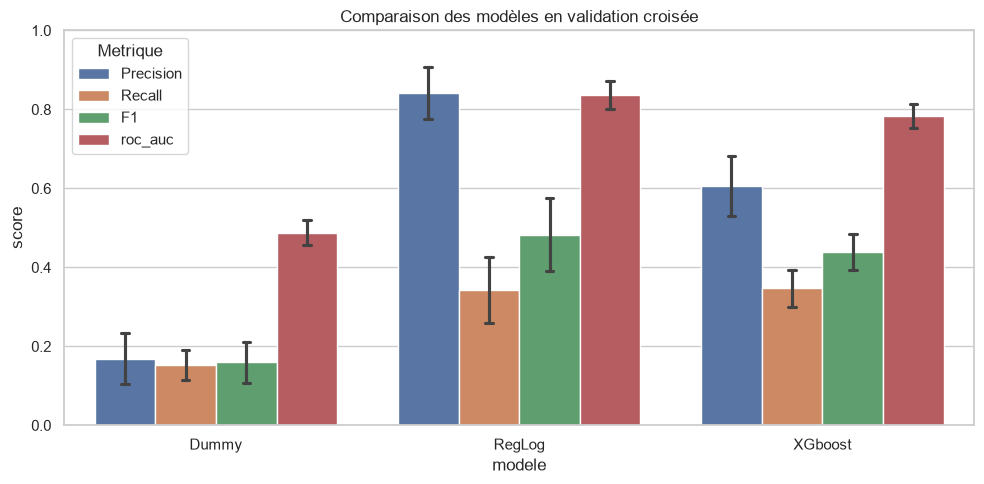

In [ ]:
sns.set_theme(style="whitegrid", palette="deep")   # style appliqué à tous tes graphiques
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=df_result_score, x="modele", y="score", hue="metrique",
    order=["Dummy", "RegLog", "XGboost"],
    errorbar="sd", capsize=0.1, ax=ax,   
)

ax.set_ylim(0, 1)
ax.set_title("Comparaison des modèles en validation croisée")
ax.legend(title="Metrique")
plt.tight_layout()
plt.show()

#### Grid search sur le modele de Regression logistique

Identification des paramètres par défaut de la regression logistique

In [41]:
LogisticRegression().get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': 0.0,
 'max_iter': 100,
 'n_jobs': None,
 'penalty': 'deprecated',
 'random_state': None,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

<table border="1" cellpadding="8" cellspacing="0">
  <thead>
    <tr>
      <th>Nom du paramètre</th>
      <th>À quoi sert-il ?</th>
      <th>Parametre par défaut</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><code>penalty</code></td>
      <td>Spécifie le type de régularisation appliqué pour éviter le surapprentissage (ex. 'l2', 'l1', 'elasticnet' ou 'none').</td>
      <td>l2</td>
    </tr>
    <tr>
      <td><code>C</code></td>
      <td>L'inverse de la force de régularisation. Des valeurs plus faibles signifient une régularisation plus forte. (valeurs possibles 0.01, 0.1, 1.0, 10, 100)</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td><code>solver</code></td>
      <td>L'algorithme d'optimisation à utiliser pour résoudre le problème (ex. 'lbfgs', 'liblinear', 'sag', 'saga').</td>
      <td>lbfgs</td>
    </tr>
    <tr>
      <td><code>max_iter</code></td>
      <td>Le nombre maximal d'itérations que l'algorithme d'optimisation est autorisé à effectuer pour converger.</td>
      <td>100</td>
    </tr>
    <tr>
      <td><code>class_weight</code></td>
      <td>Permet de donner plus de poids à certaines classes si ton jeu de données est déséquilibré (ex. 'balanced').</td>
      <td>None</td>
    </tr>
  </tbody>
</table>

Les parametres a modifier pour améliorer les scores :   
* C qui prend une valeur par défaut de 1 a modifier en 0.1 pour avoir une régularisation plus forte
* class_weight (par défaut None) passer le parametre a balanced
* solver (par defaut lbfgs) passer le parametre en liblinear (adapté aux classifications binaires)

Grid search : Grille 1 (C à 0.1 et class_weight à balanced) + scores

Grid search : Grille 2 (C à 0.1 et solver à liblinear) + scores

### 6 - Entrainement du meilleur modele : Regression Logistique

### 7 - Evaluation du modele

Scores de l'entrainement et de la prédiction

Adaptation du seuil de probabilité (défaut 50) et recalcul des scores

Courbe précision/rappel sur les meilleurs résultats  
L'intéret de cette courbe est de savoir comment améliorer les scores trouvés 

### 8 - Analyse des résultats

Courbe ROC_AUC (voir les prédictions et leur probabilités)

#### Feature importance

Méthode SHAP

Graphique de Beeswarm